# 01. Data Audit and EDA

This notebook verifies the processed graphs in `data/processed/` (`facebook_1`–`facebook_5` and `synthetic_beta_*`):
1. Verify graph connectivity, feature dimensions, and leak-free 80/10/10 splits.
2. Compare local Facebook graph statistics against Table 4 reference values (Pisacane et al., LoG 2024).
3. Analyze node degree distributions and clustering coefficients (community structure).

In [1]:
import os
import sys
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

from src.data.audit import TABLE_4_GROUND_TRUTH, audit_processed_graph
from src.data.splits import load_splits_and_pairs

sns.set_theme(style="whitegrid")
print(f"Project root: {PROJECT_ROOT}")

Project root: E:\Studia\9_semestr\Computational Intelligence\project


## 1. Audit of All Processed Graphs

In [2]:
processed_dir = Path("data/processed")
graph_dirs = sorted([d for d in processed_dir.iterdir() if d.is_dir() and (d / "graph.pkl").exists()])

audit_rows = []
for gdir in graph_dirs:
    stats = audit_processed_graph(str(gdir))
    stats["train_n"] = stats["split_counts"]["train"]
    stats["val_n"] = stats["split_counts"]["val"]
    stats["test_n"] = stats["split_counts"]["test"]
    audit_rows.append(stats)

df_audit = pd.DataFrame(audit_rows).drop(columns=["split_counts"])
display(df_audit)

,name,nodes,edges,is_connected,density,avg_shortest_path,attribute_dim,leak_free,val_target_purity,test_target_purity,feature_check_passed,train_n,val_n,test_n
0,facebook_1,148,1692,True,0.1555,2.6916,105,True,True,True,True,118,15,15
1,facebook_2,168,1656,True,0.1180,2.4251,63,True,True,True,True,134,17,17
2,facebook_3,224,3192,True,0.1278,2.5235,161,True,True,True,True,179,22,23
3,facebook_4,324,2514,True,0.0480,3.7527,224,True,True,True,True,259,32,33
4,facebook_5,532,4812,True,0.0341,3.4474,262,True,True,True,True,426,53,53
5,synthetic_beta_0p1,200,246,True,0.0124,6.5832,2,True,True,True,True,160,20,20
6,synthetic_beta_0p4,200,315,True,0.0158,5.9427,2,True,True,True,True,160,20,20
7,synthetic_beta_1p0,200,415,True,0.0209,5.3224,2,True,True,True,True,160,20,20
8,synthetic_beta_5p0,200,958,True,0.0481,4.3913,2,True,True,True,True,160,20,20


## 2. Comparison with Table 4 (Pisacane et al., 2024)

In [3]:
comparison_rows = []
for name, ref in TABLE_4_GROUND_TRUTH.items():
    local = df_audit[df_audit["name"] == name]
    if local.empty:
        continue
    row = local.iloc[0]
    comparison_rows.append({
        "graph": name,
        "ego_id": ref["ego_id"],
        "n_local": int(row["nodes"]),
        "n_paper": ref["n"],
        "avg_sp_local": round(float(row["avg_shortest_path"]), 2),
        "avg_sp_paper": ref["avg_sp"],
        "density_local": round(float(row["density"]), 2),
        "density_paper": ref["density"],
        "dim_local": int(row["attribute_dim"]),
        "dim_paper": ref["d"],
    })

df_cmp = pd.DataFrame(comparison_rows)
display(df_cmp)

,graph,ego_id,n_local,n_paper,avg_sp_local,avg_sp_paper,density_local,density_paper,dim_local,dim_paper
0,facebook_1,414,148,148,2.69,2.69,0.16,0.16,105,105
1,facebook_2,686,168,168,2.43,2.43,0.12,0.12,63,63
2,facebook_3,348,224,224,2.52,2.52,0.13,0.13,161,161
3,facebook_4,0,324,324,3.75,3.75,0.05,0.05,224,224
4,facebook_5,3437,532,532,3.45,3.45,0.03,0.03,262,262


## 3. Degree Distribution and Clustering Coefficient (Facebook Ego-Networks)

C:\Users\barju\AppData\Local\Temp\ipykernel_32360\2382449392.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clust, x="graph", y="avg_clustering", ax=axes[1], palette="viridis")


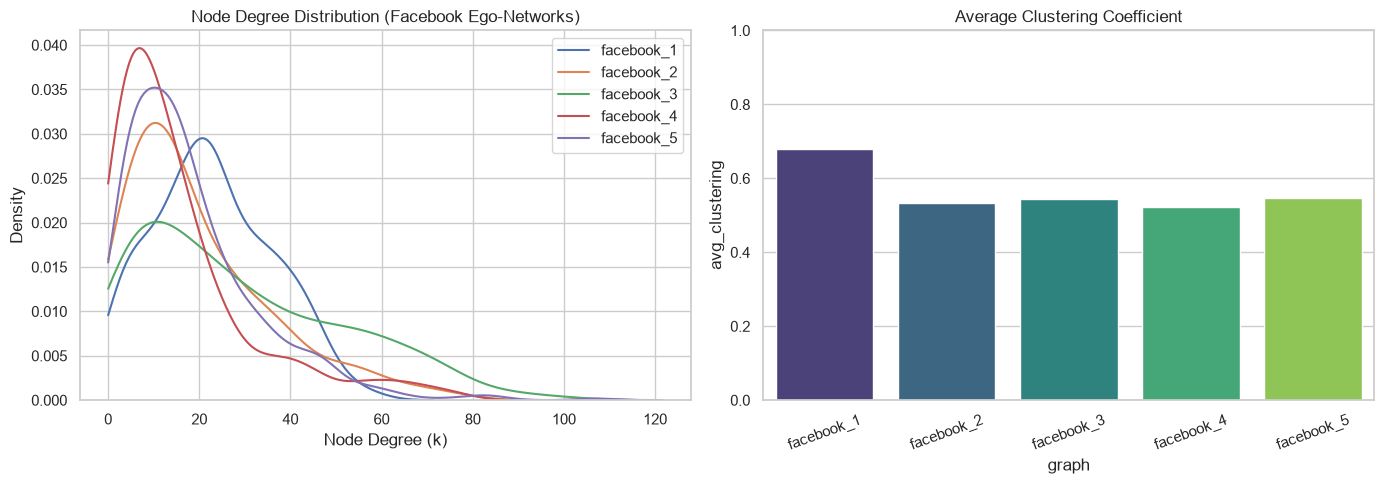

,graph,mean_degree,max_degree,avg_clustering,transitivity
0,facebook_1,22.864865,57,0.6794,0.6458
1,facebook_2,19.714286,77,0.5338,0.4536
2,facebook_3,28.500000,99,0.5443,0.4903
3,facebook_4,15.518519,77,0.5224,0.4259
4,facebook_5,18.090226,107,0.5458,0.4489


In [4]:
fb_dirs = [d for d in graph_dirs if d.name.startswith("facebook_")]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
clustering_summary = []

for gdir in fb_dirs:
    with open(gdir / "graph.pkl", "rb") as f:
        g = pickle.load(f)
    degrees = [deg for _, deg in g.degree()]
    avg_clust = nx.average_clustering(g)
    transitivity = nx.transitivity(g)
    clustering_summary.append({
        "graph": gdir.name,
        "mean_degree": np.mean(degrees),
        "max_degree": np.max(degrees),
        "avg_clustering": round(avg_clust, 4),
        "transitivity": round(transitivity, 4),
    })
    sns.kdeplot(degrees, ax=axes[0], label=gdir.name, clip=(0, None))

axes[0].set_title("Node Degree Distribution (Facebook Ego-Networks)")
axes[0].set_xlabel("Node Degree (k)")
axes[0].legend()

df_clust = pd.DataFrame(clustering_summary)
sns.barplot(data=df_clust, x="graph", y="avg_clustering", ax=axes[1], palette="viridis")
axes[1].set_title("Average Clustering Coefficient")
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()
display(df_clust)